# Лабораторная работа № 3 — задание 2

Выполняли Свешников Борис — ИСУ 467394 и Хасанов Дмитрий — ИСУ 467920.

$$4+6+7+3+9+4=33,\qquad4+6+7+9+2+0=28,$$

$$(33+28)\bmod5+1=2$$


## Условие задания

Постройте два асимптотических доверительных интервала уровня $1-\alpha$ для указанного параметра. Проведите эксперимент по схеме, аналогичной первой задаче, и сравните два доверительных интервала.

Задача представлена в 5 вариантах. Сначала указывается класс распределений (однопараметрический) и оцениваемый параметр, затем параметры эксперимента и подсказки.

**Вариант 2.**

- Класс распределений: распределение Лапласса с неизвестным параметром сдвига $\mu$ и единичным масштабирующим параметром.
- Оцениваемый параметр: $\mu$.
- Параметры эксперимента: $\mu=2$.
- Подсказка: асимптотическая нормальность выборочных среднего и медианы.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import Image, Markdown, display

from utils.intervals import (
    laplace_intervals, laplace_mean_coverage, laplace_median_coverage,
)
from utils.experiments import run_laplace_experiment, paired_coverage_difference
from plots.laplace import laplace_theory_plots, laplace_result_plots

SEED = 24422442
ALPHA = 0.05
MU = 2.0
SCALE = 1.0
M = 20_000
# Нечётные n задают медиану как единственную центральную порядковую статистику.
N = np.array([3, 5, 11, 21, 51, 101, 301, 1001, 3001])
OUTPUT_DIR = Path("images/laplace_location")
pd.set_option("display.max_columns", 16)
pd.set_option("display.width", 160)
q = stats.norm.ppf(1-ALPHA/2)


## Модель Лапласа: плотность, функция распределения и моменты

Запишем плотность сначала с произвольным масштабом $b>0$:

$$f_{\mu,b}(x)=\frac1{2b}\exp\left(-\frac{|x-\mu|}{b}\right),\qquad x\in\mathbb R.$$

В нашей задаче $b=1$ известен, поэтому это однопараметрическая модель по $\mu$:

$$f_{\mu,1}(x)=\frac12\exp\left(-|x-\mu|\right).$$

Положим $W=X-\mu$. Распределение $W$ симметрично относительно нуля, поэтому $\mathbb EW=0$ и $\mathbb EX=\mu$.

Используя симметрию плотности, замену $u=t/b$ и равенство $\int_0^\infty u^2e^{-u}du=\Gamma(3)=2$, получаем

$$\operatorname{Var}(X)=\mathbb E(X-\mu)^2=\mathbb EW^2
=2\int_0^\infty t^2\frac1{2b}e^{-t/b}\,dt
=b^2\int_0^\infty u^2e^{-u}\,du
=\boxed{2b^2}.$$

В частности, при $b=1$ имеем $\operatorname{Var}(X)=2$.

Интегрируя плотность слева и справа от $\mu$, получаем

$$F_{\mu,b}(x)=\begin{cases}
\frac12 e^{(x-\mu)/b},&x\le\mu,\\
1-\frac12 e^{-(x-\mu)/b},&x>\mu.
\end{cases}$$

Следовательно, $F_{\mu,b}(\mu)=1/2$, то есть **медиана также равна $\mu$**, а $p_{\mu,b}(\mu)=1/(2b)$. 

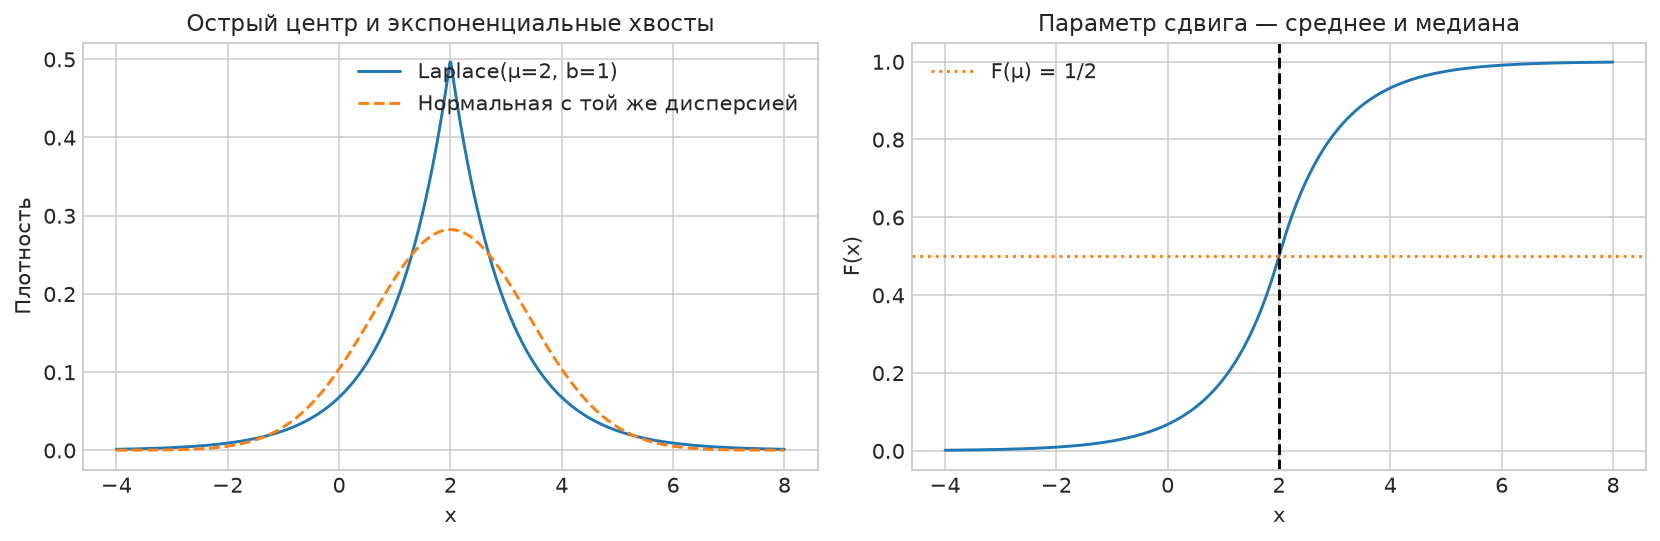

In [2]:
theory_images = laplace_theory_plots(OUTPUT_DIR)
display(Image(filename=str(theory_images["model"])))

## Первый интервал: выборочное среднее

Выборочное среднее равно

$$\overline X_n=\frac1n\sum_{i=1}^nX_i.$$

По линейности ожидания $\mathbb E\overline X_n=\mu$. В силу независимости

$$\operatorname{Var}(\overline X_n)
=\frac1{n^2}\sum_{i=1}^n\operatorname{Var}(X_i)=\frac{2b^2}{n}.$$

По центральной предельной теореме

$$\sqrt n(\overline X_n-\mu)\xrightarrow d\mathcal N(0,2b^2),$$

$$T_n^{(\mathrm{mean})}=\frac{\sqrt n(\overline X_n-\mu)}{\sqrt2\,b}
\xrightarrow d\mathcal N(0,1).$$

Пусть $q=q_{1-\alpha/2}=\Phi^{-1}(1-\alpha/2)>0$. Тогда

$$\mathbb P\left(-q\le\frac{\sqrt n(\overline X_n-\mu)}{\sqrt2\,b}\le q\right)\longrightarrow1-\alpha.$$

$$I_{\mathrm{mean}}=
\left[\overline X_n-qb\sqrt{\frac2n},\quad
\overline X_n+qb\sqrt{\frac2n}\right].$$

При $b=1$ неизвестных параметров в интервале нет.

## Второй интервал: выборочная медиана

Для $n=2k-1$ определяем медиану как центральную порядковую статистику

$$\widetilde X_n=X_{(k)},\qquad k=(n+1)/2.$$

Для $p(\mu)>0$ выборочная медиана асимптотически нормальна (теорема об асимптотике ср членов вар ряда):

$$\sqrt n(\widetilde X_n-\mu)\xrightarrow d\mathcal N\left(0,\frac1{4p(\mu)^2}\right).$$

Для Лапласа $p(\mu)=1/(2b)$, поэтому $1/[4p(\mu)^2]=b^2$ и

$$\sqrt n(\widetilde X_n-\mu)\xrightarrow d\mathcal N(0,b^2).$$

$$\frac{\sqrt n(\widetilde X_n-\mu)}b\xrightarrow d\mathcal N(0,1)$$

$$-q\le\frac{\sqrt n(\widetilde X_n-\mu)}b\le q.$$

$$I_{\mathrm{median}}=
\left[\widetilde X_n-\frac{qb}{\sqrt n},\quad
\widetilde X_n+\frac{qb}{\sqrt n}\right].$$

При заданном $b$ неизвестных параметров нет.

In [3]:
rng_demo = np.random.default_rng(SEED + 101)
sample = rng_demo.laplace(MU, SCALE, size=11)
intervals = laplace_intervals(sample, ALPHA, SCALE)
print("Наблюдения:", np.round(sample, 3))
print(f"Среднее: {sample.mean():.6f}; медиана: {np.median(sample):.6f}")
for method, (low, high) in intervals.items():
    print(f"{method:6s}: [{low:.6f}, {high:.6f}], длина={high-low:.6f}, накрывает μ: {bool(low <= MU <= high)}")

Наблюдения: [ 4.123  2.517 -0.722  2.902  1.399  1.748  1.133  2.402  2.832  2.584
  1.836]
Среднее: 2.068432; медиана: 2.402404
mean  : [1.232700, 2.904163], длина=1.671463, накрывает μ: True
median: [1.811452, 2.993355], длина=1.181903, накрывает μ: True


### Точное покрытие и сходимость к нормальному распределению

Сначала сравним точные конечновыборочные вероятности покрытия обоих асимптотических интервалов. Затем для одинаковых $n$ сопоставим точные плотности стандартизованных среднего и медианы с предельной плотностью $\mathcal N(0,1)$.

In [4]:
reference = pd.DataFrame({
    "n": N,
    "mean_exact_coverage": [laplace_mean_coverage(int(n), ALPHA) for n in N],
    "median_exact_coverage": [laplace_median_coverage(int(n), ALPHA) for n in N],
})
display(reference.round(6))

,n,mean_exact_coverage,median_exact_coverage
0,3,0.943417,0.860744
1,5,0.945642,0.871317
2,11,0.947876,0.890234
3,21,0.948865,0.904356
4,51,0.949529,0.919551
5,101,0.949762,0.928039
6,301,0.949920,0.937139
7,1001,0.949976,0.942918
8,3001,0.949992,0.945905


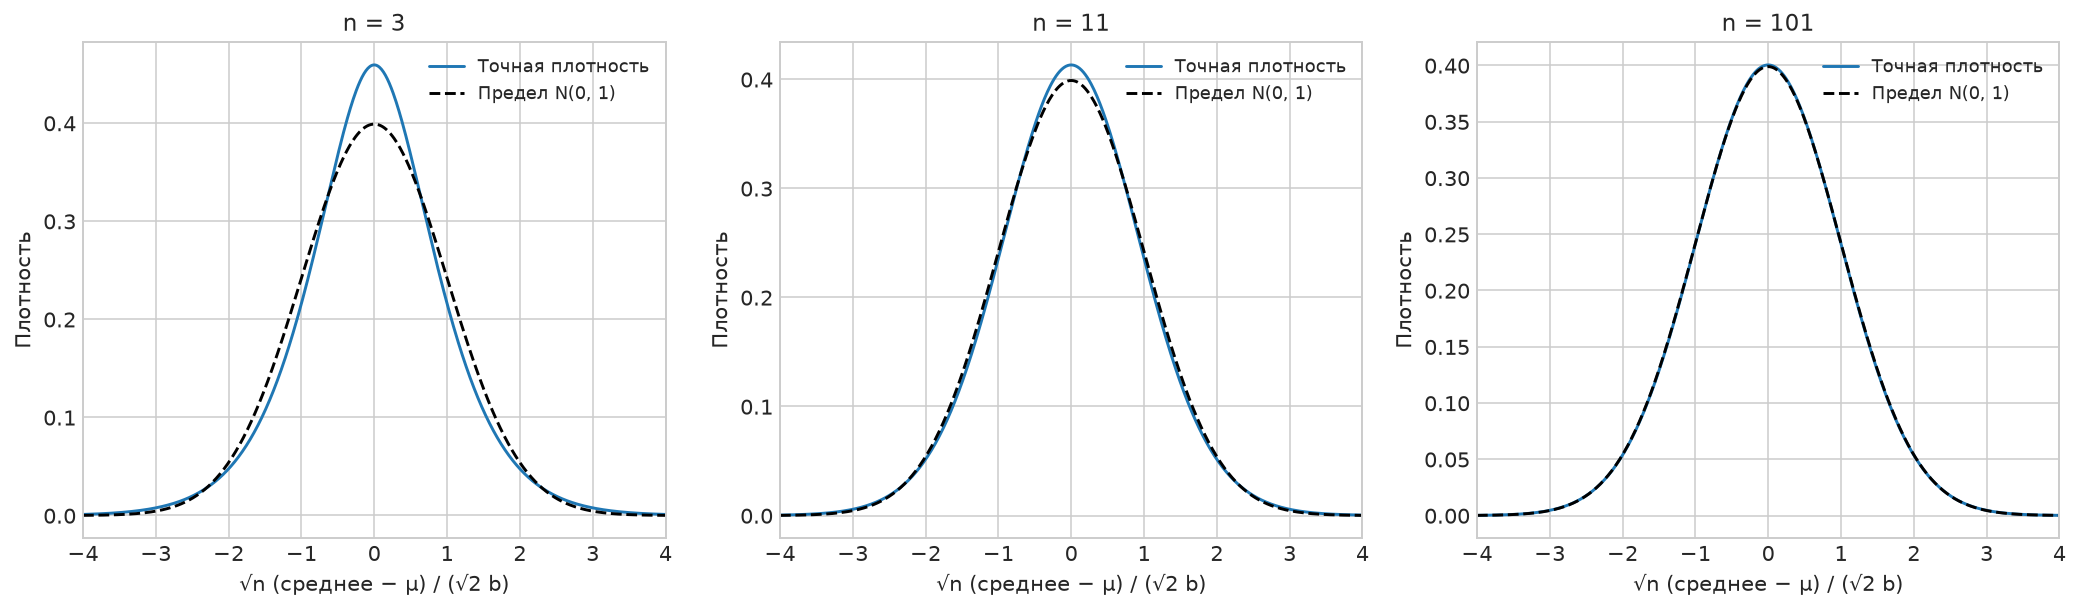

In [5]:
display(Image(filename=str(theory_images["mean_limit"])))

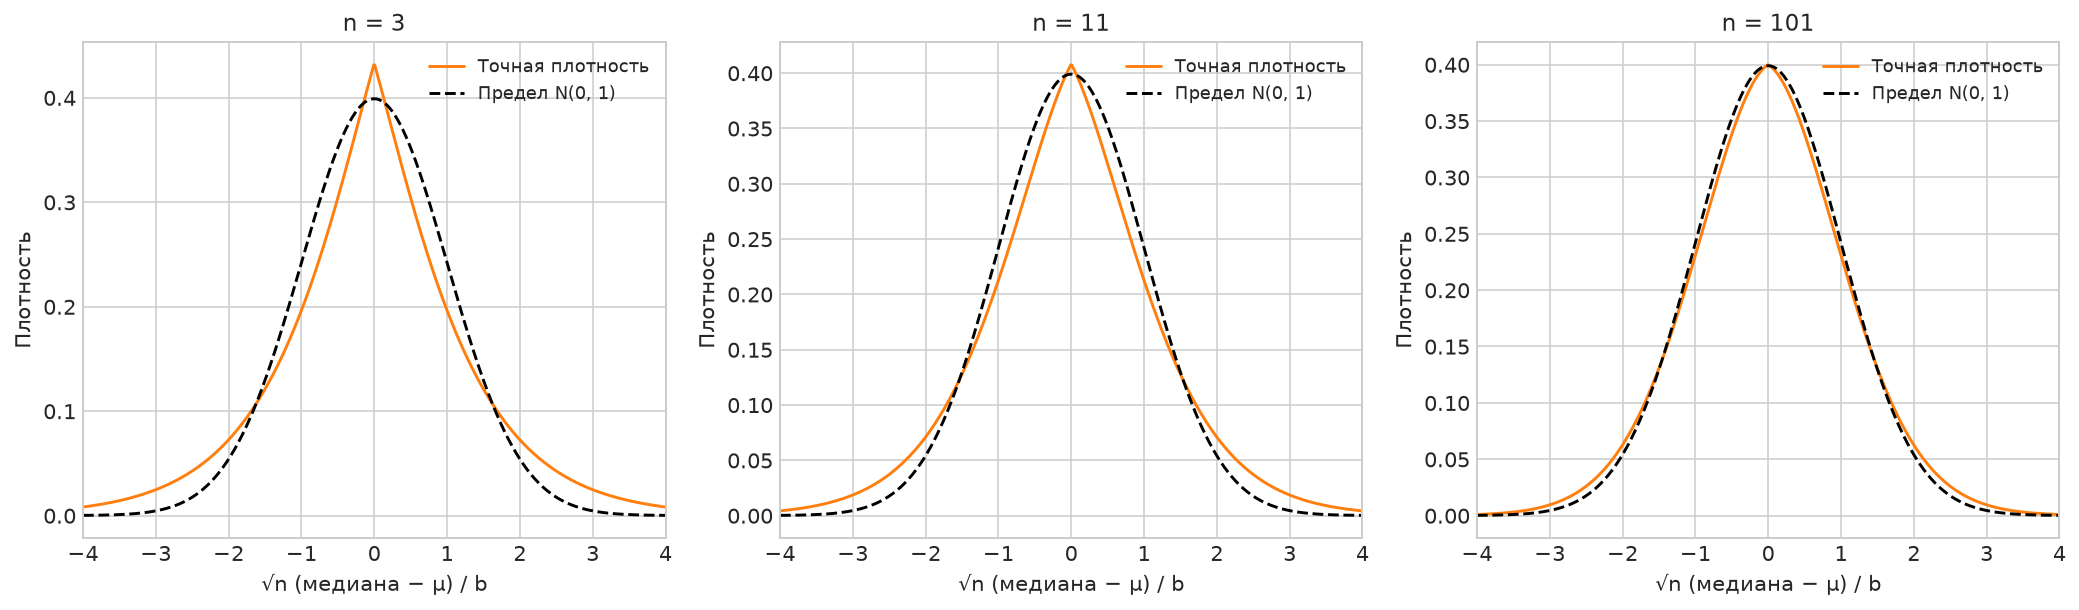

In [6]:
display(Image(filename=str(theory_images["median_limit"])))

## Вычислительный эксперимент

Для каждого $n$ генерируем $M=20000$ независимых выборок $X_i\sim\operatorname{Laplace}(2,1)$.
**На одной и той же выборке** вычисляем среднее, медиану и оба интервала: это парное сравнение.
Случайные генераторы для двух заданий и для демонстрационных примеров используют отдельные фиксированные seed, поэтому примеры не меняют основной эксперимент.

Для каждого метода считаем:

$$\widehat c=\frac1M\sum_{j=1}^M\mathbb1(L_j\le\mu\le U_j),\qquad
\widehat{\operatorname{Bias}}=\frac1M\sum_j(\widehat\mu_j-\mu),$$

$$\widehat{\operatorname{Var}}=\frac1{M-1}\sum_j(\widehat\mu_j-\overline{\widehat\mu})^2,
\qquad
\widehat{\operatorname{MSE}}=\frac1M\sum_j(\widehat\mu_j-\mu)^2.$$

In [7]:
experiment = run_laplace_experiment(N, M, SEED+2, ALPHA, MU)
table = experiment["table"]
paired = paired_coverage_difference(experiment)
result_images = laplace_result_plots(experiment, paired, OUTPUT_DIR)
display(table[["n", "method", "coverage", "mc_low", "mc_high", "exact_coverage", "mean_length", "bias", "variance", "mse"]].round(6))

,n,method,coverage,mc_low,mc_high,exact_coverage,mean_length,bias,variance,mse
0,3,mean,0.94240,0.939085,0.945545,0.943417,3.200608,0.000159,0.678086,0.678052
1,3,median,0.85895,0.854057,0.863705,0.860744,2.263171,0.004998,0.654581,0.654573
2,5,mean,0.94750,0.944322,0.950506,0.945642,2.479180,0.003061,0.395763,0.395752
3,5,median,0.87100,0.866283,0.875574,0.871317,1.753045,0.001726,0.346824,0.346810
4,11,mean,0.94685,0.943654,0.949874,0.947876,1.671463,0.004205,0.181768,0.181777
5,11,median,0.88925,0.884826,0.893525,0.890234,1.181903,0.002536,0.139075,0.139075
6,21,mean,0.94745,0.944271,0.950457,0.948865,1.209716,0.000519,0.095466,0.095461
7,21,median,0.90570,0.901571,0.909673,0.904356,0.855398,0.000900,0.065885,0.065882
8,51,mean,0.94835,0.945196,0.951332,0.949529,0.776261,0.001279,0.039365,0.039365
9,51,median,0.91795,0.914066,0.921674,0.919551,0.548900,0.001462,0.024248,0.024249


## Покрытие: главный результат сравнения

Точки с полосами на первом рисунке — Монте-Карло, сплошная линия у медианы — конечновыборочная вероятность по выведенной формуле.
Поэтому систематическое отставание медианного интервала от $0.95$ не следует объяснять только случайностью симуляции.

В этой модели асимптотическое приближение медианы сходится заметно медленнее: при $n=3$ фактическое покрытие около $0.861$, при $n=101$ около $0.928$, при $n=1001$ около $0.943$.
Даже при $n=3001$ оно около $0.946$, а не ровно $0.95$.
У среднего в эксперименте покрытие от $0.942$ при $n=3$ до $0.95$ при больших $n$: отклонение от номинала намного меньше, чем у медианы.
Для медианы указаны значения точной вероятности, а не результата случайного запуска.

Медианный интервал действительно короче, но на небольших выборках часть выигрыша в длине сопровождается недопокрытием.
Сравнение методов требует одновременно учитывать обе характеристики.

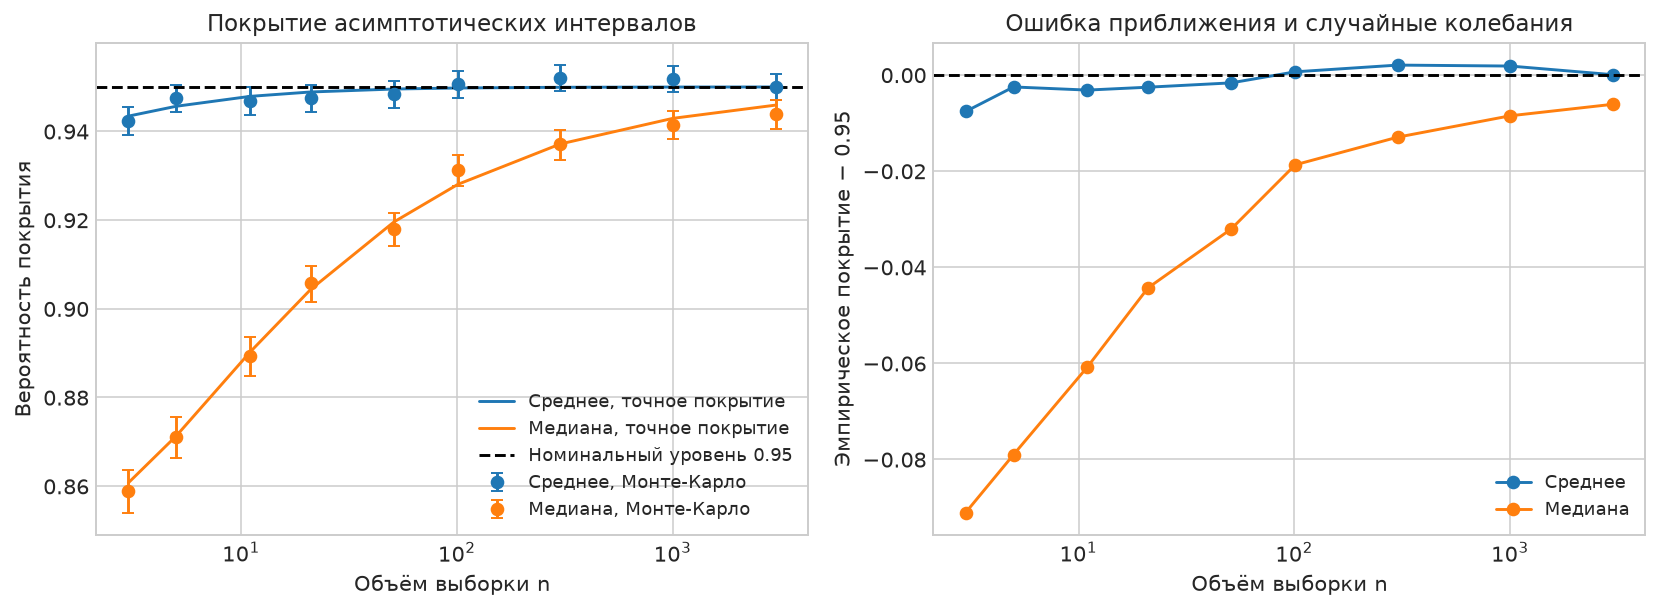

In [8]:
display(Image(filename=str(result_images["coverage"])))

## Рисуем интервалы

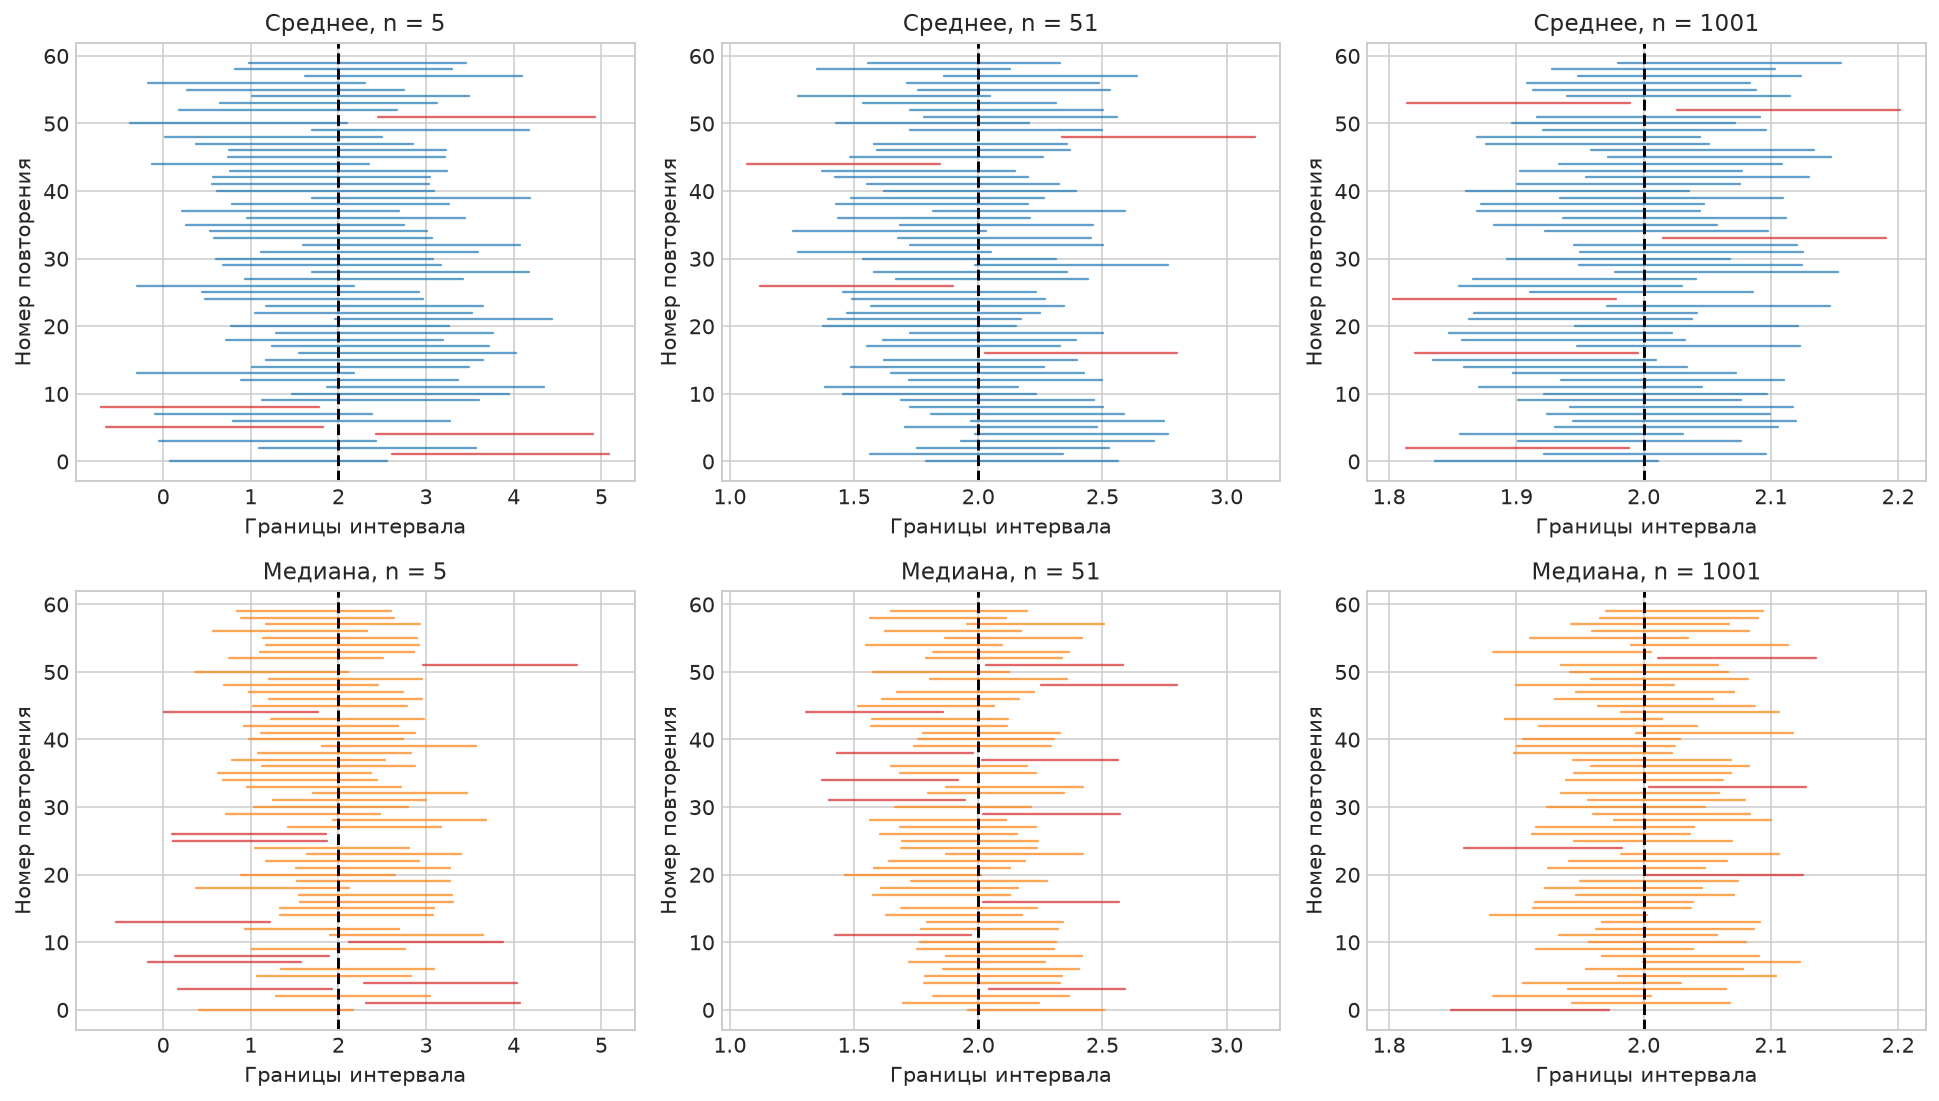

In [9]:
display(Image(filename=str(result_images["intervals"])))

## Длины и скорость сужения

Обе длины имеют точную зависимость $C/\sqrt n$ уже как функции построенных интервалов, независимо от того, насколько хорошо выполняется нормальная аппроксимация:

$$\sqrt n\,\ell_{\mathrm{mean}}=2q\sqrt2,\qquad
\sqrt n\,\ell_{\mathrm{median}}=2q.$$

Поэтому на нормированном графике получаются горизонтальные линии.
В отличие от первого задания, длины здесь не случайны и не имеют тяжёлого хвоста: масштаб известен.
Чтобы вдвое уменьшить длину любого из двух интервалов, надо увеличить $n$ в четыре раза.

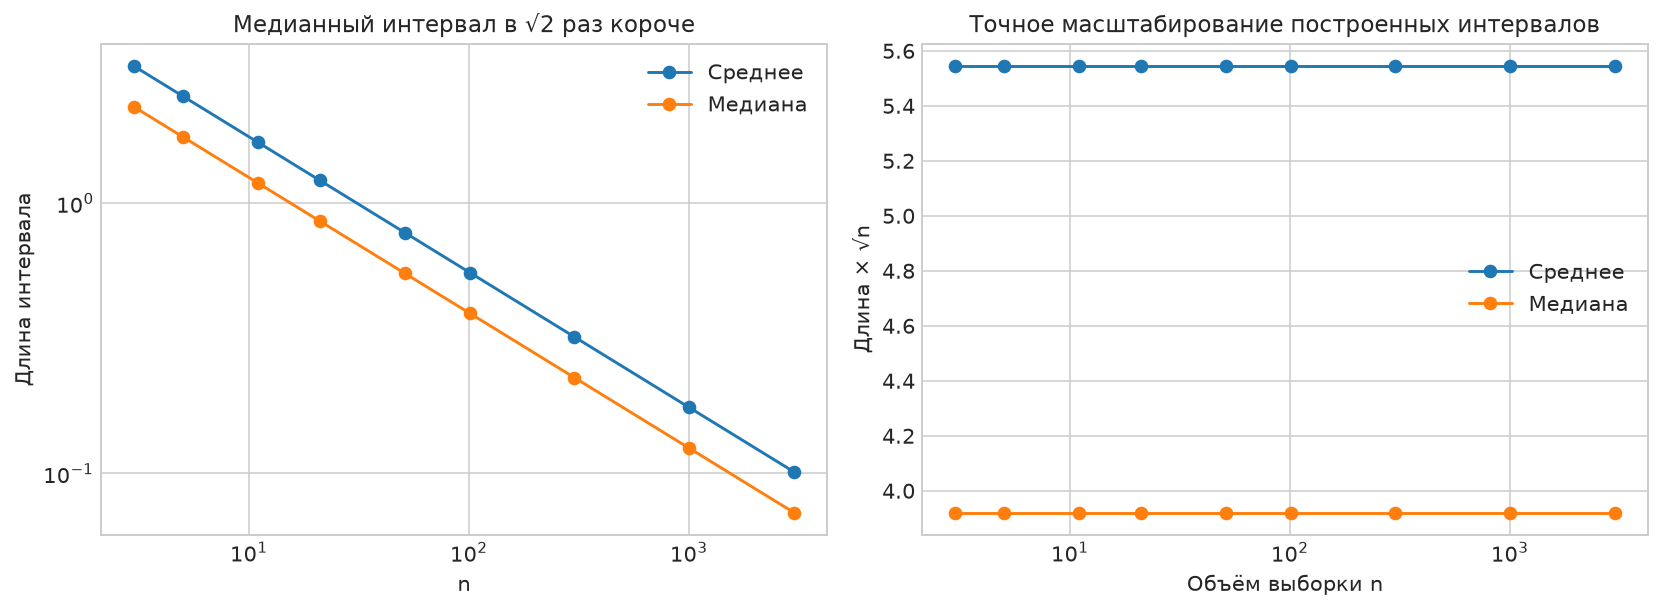

Отношение длин на всех объёмах: [0.707107 0.707107 0.707107 0.707107 0.707107 0.707107 0.707107 0.707107
 0.707107]


In [10]:
display(Image(filename=str(result_images["length"])))
mean_lengths = table[table.method == "mean"].set_index("n").mean_length
median_lengths = table[table.method == "median"].set_index("n").mean_length
np.testing.assert_allclose(median_lengths/mean_lengths, 1/np.sqrt(2))
print("Отношение длин на всех объёмах:", np.round((median_lengths/mean_lengths).to_numpy(), 6))

## Разброс оценок и MSE

Для среднего $n\operatorname{Var}(\overline X_n)=2$ при любом $n$.
Для медианы асимптотически $n\operatorname{Var}(\widetilde X_n)\to1$; сходимость по распределению сама по себе не гарантирует сходимости дисперсий, поэтому здесь это проверяется по эксперименту.

На левой панели проверяем нормированные дисперсии, на правой — MSE и асимптотические ориентиры $2/n$, $1/n$.
Несмещённость не означает отсутствия колебаний эмпирического смещения на конечных $M$.

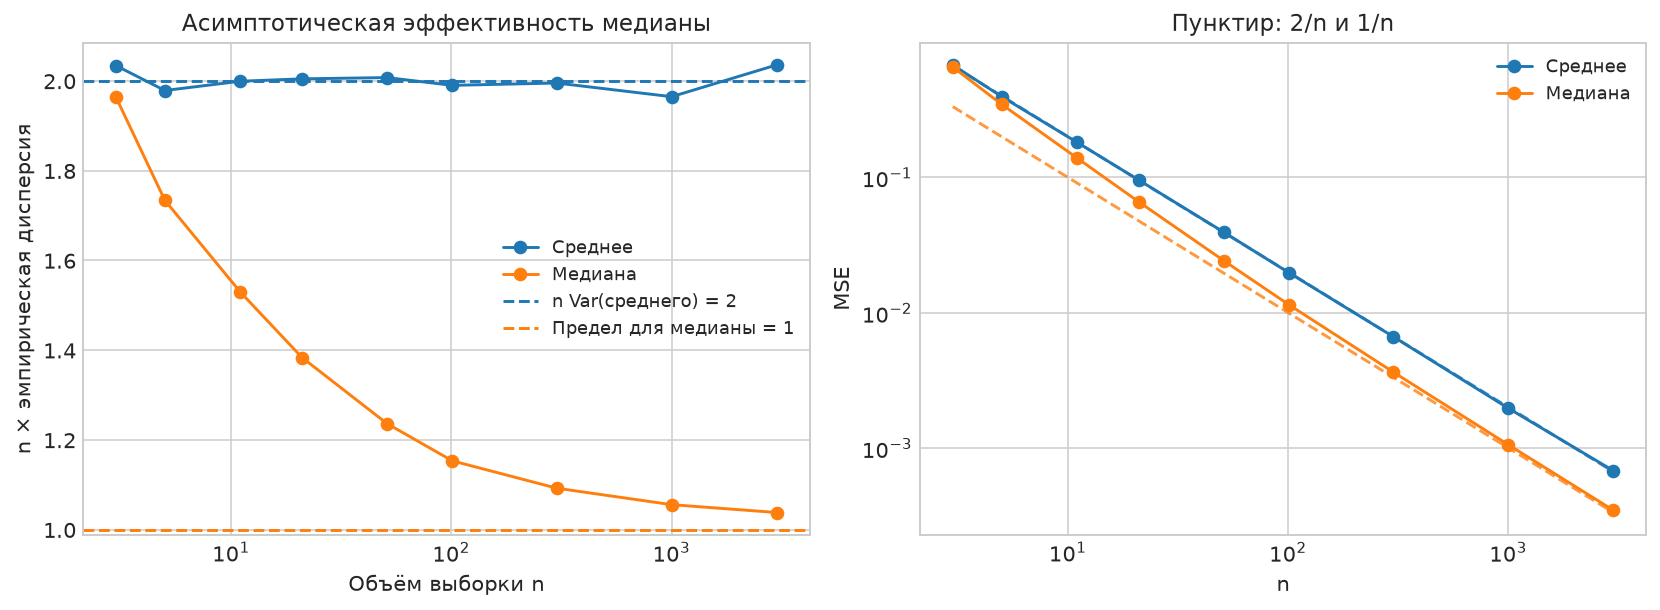

In [11]:
display(Image(filename=str(result_images["variance"])))

## Форма распределений ошибок

Для корректного сравнения нормируем каждую оценку её собственной асимптотической стандартной ошибкой:

$$T_n^{(\mathrm{mean})}=\sqrt{n/2}(\overline X_n-\mu),\qquad
T_n^{(\mathrm{median})}=\sqrt n(\widetilde X_n-\mu).$$

Обе величины должны сходиться к $\mathcal N(0,1)$.
Гистограммы показывают центральную форму, а Q–Q графики лучше выявляют расхождение в хвостах, которые определяют покрытие.
Если хвосты стандартизованной ошибки шире нормальных, фиксированные пороги $\pm1.96$ пропускают больше $5\%$ реализаций.
На больших объёмах отличие медианного распределения становится небольшим визуально, но всё ещё заметным по точным вероятностям покрытия.

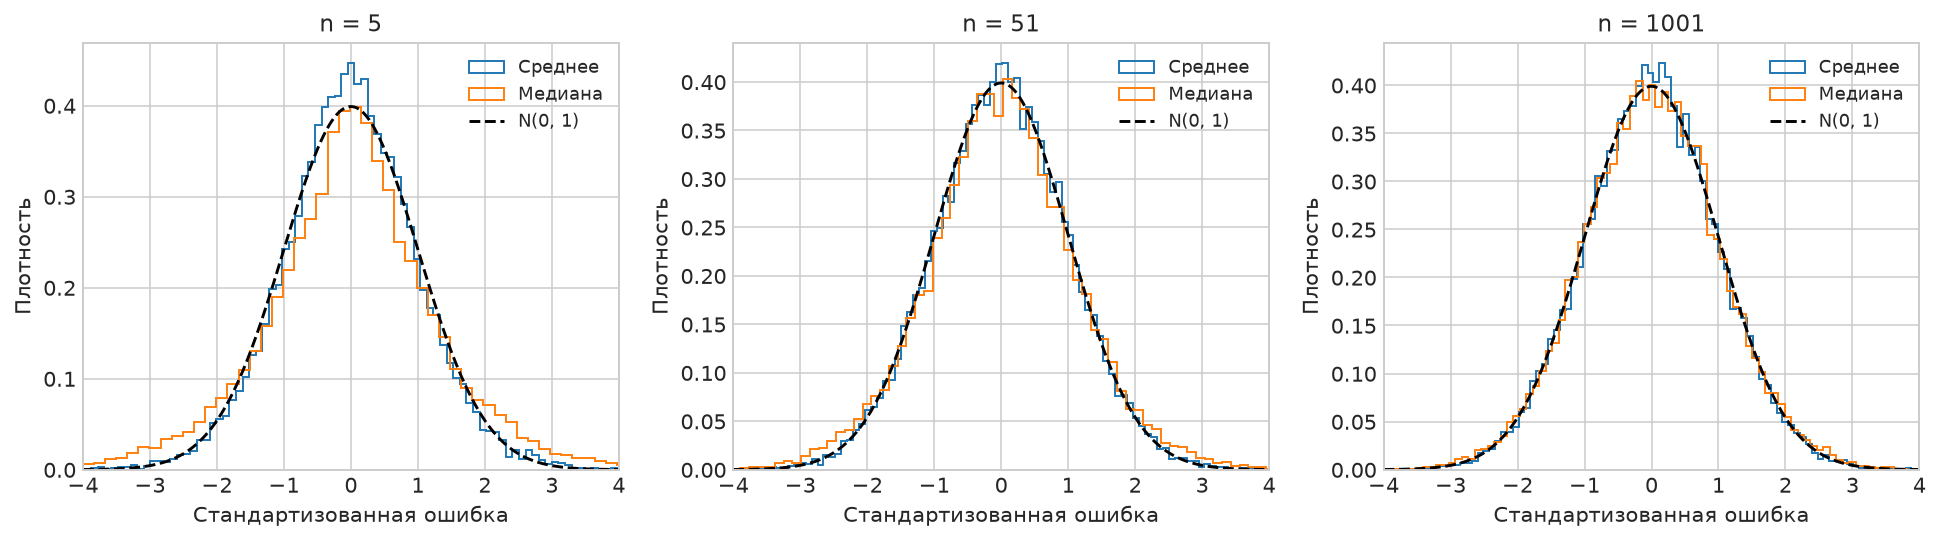

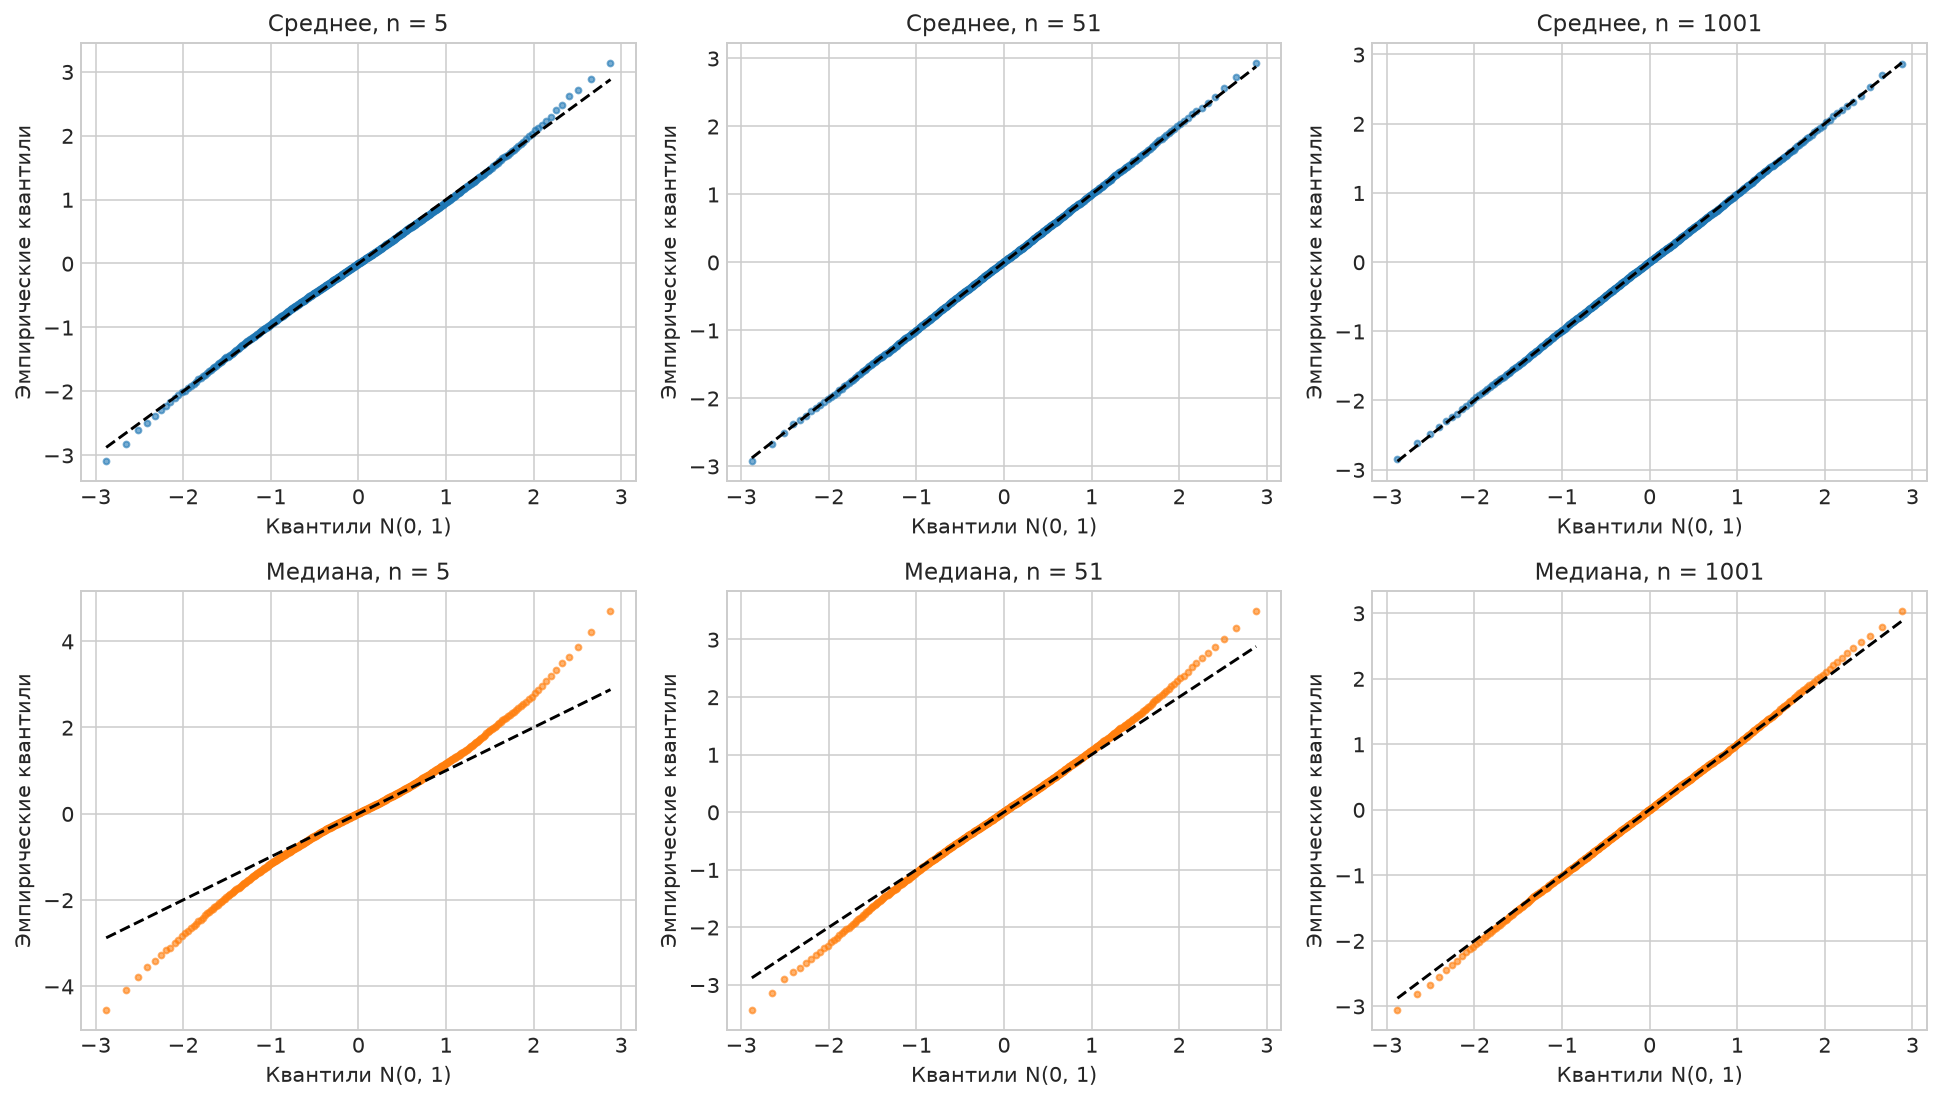

In [12]:
display(Image(filename=str(result_images["distribution"])))
display(Image(filename=str(result_images["qq"])))

## Симметрия, смещение и границы

Благодаря симметрии распределения и симметричности полуширины

$$\mathbb P(U<\mu)=\mathbb P(L>\mu)=\frac{1-c(n)}2.$$

Для точного $95\%$ покрытия оба хвоста были бы по $2.5\%$; при недопокрытии оба превышают это значение одновременно.
Такой рисунок отличается от ситуации со смещённой оценкой, когда один хвост систематически доминирует над другим.

На панели смещения ориентиром служат полосы $\pm1.96\sqrt{\widehat{\operatorname{Var}}(\widehat\mu)/M}$.
Это оценка масштаба шума среднего по $M$ реализациям, а не доверительный интервал для исходного $\mu$.
На рисунках границ полосы 10–90% отражают разброс отдельных границ, а не ошибку их средних.

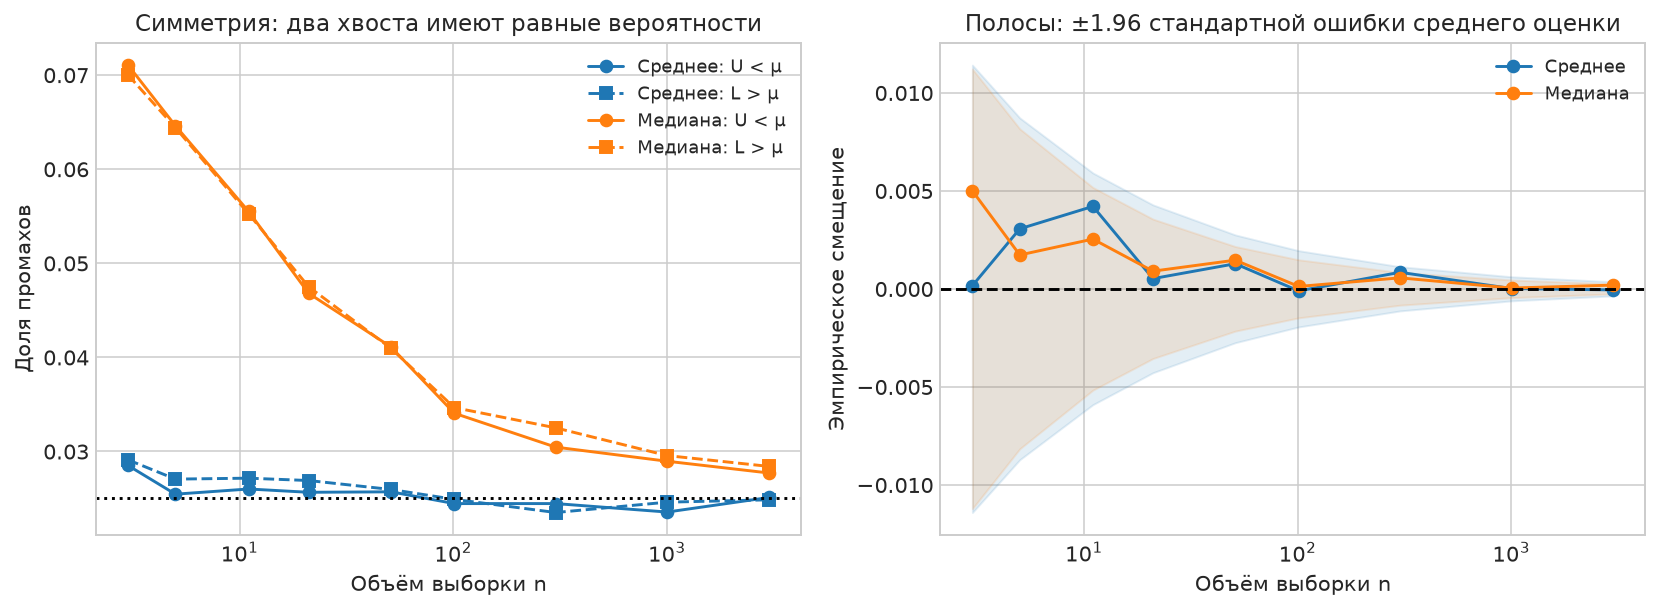

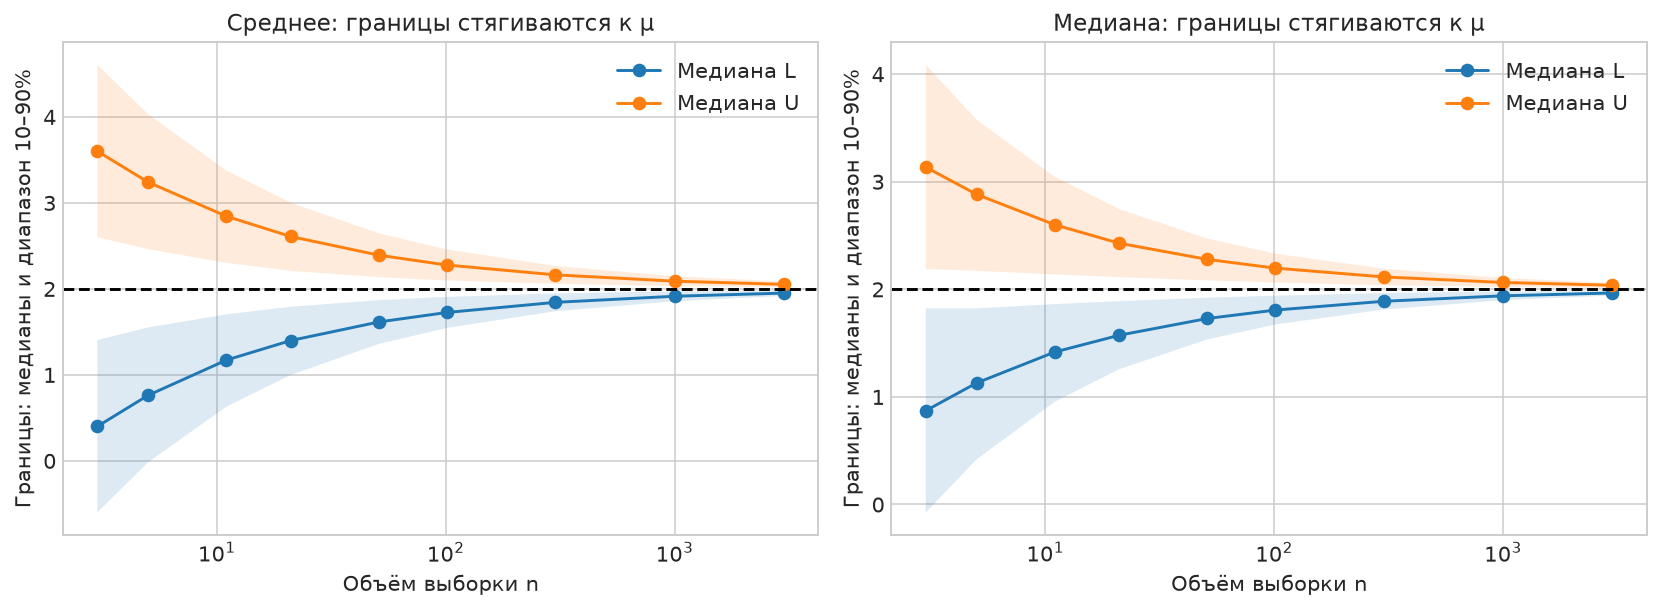

In [13]:
display(Image(filename=str(result_images["tails_bias"])))
display(Image(filename=str(result_images["bounds"])))

## Парное сравнение покрытия

Две процедуры применяются к одним данным, поэтому индикаторы покрытия коррелированы.
Для каждого повторения определим

$$D_j=\mathbb1\{\mu\in I_{\mathrm{median},j}\}-\mathbb1\{\mu\in I_{\mathrm{mean},j}\}\in\{-1,0,1\}.$$

Тогда

$$\widehat\Delta=\frac1M\sum_jD_j,\qquad
\widehat{\operatorname{SE}}(\widehat\Delta)
=\frac{s_D}{\sqrt M},\qquad
s_D^2=\frac1{M-1}\sum_j(D_j-\overline D)^2.$$

Именно эту парную стандартную ошибку используем в полосах на рисунке, а не формулу для двух независимых экспериментов.
Отрицательная разность означает меньшее покрытие медианного интервала.
Это сравнение покрытий, а не попытка выбрать метод только по числу «успешных» повторений.

,n,difference,paired_se
0,3,-0.08345,0.002332
1,5,-0.07650,0.002349
2,11,-0.05760,0.002243
3,21,-0.04175,0.002154
4,51,-0.03040,0.002070
5,101,-0.01935,0.001918
6,301,-0.01500,0.001896
7,1001,-0.01035,0.001851
8,3001,-0.00615,0.001896


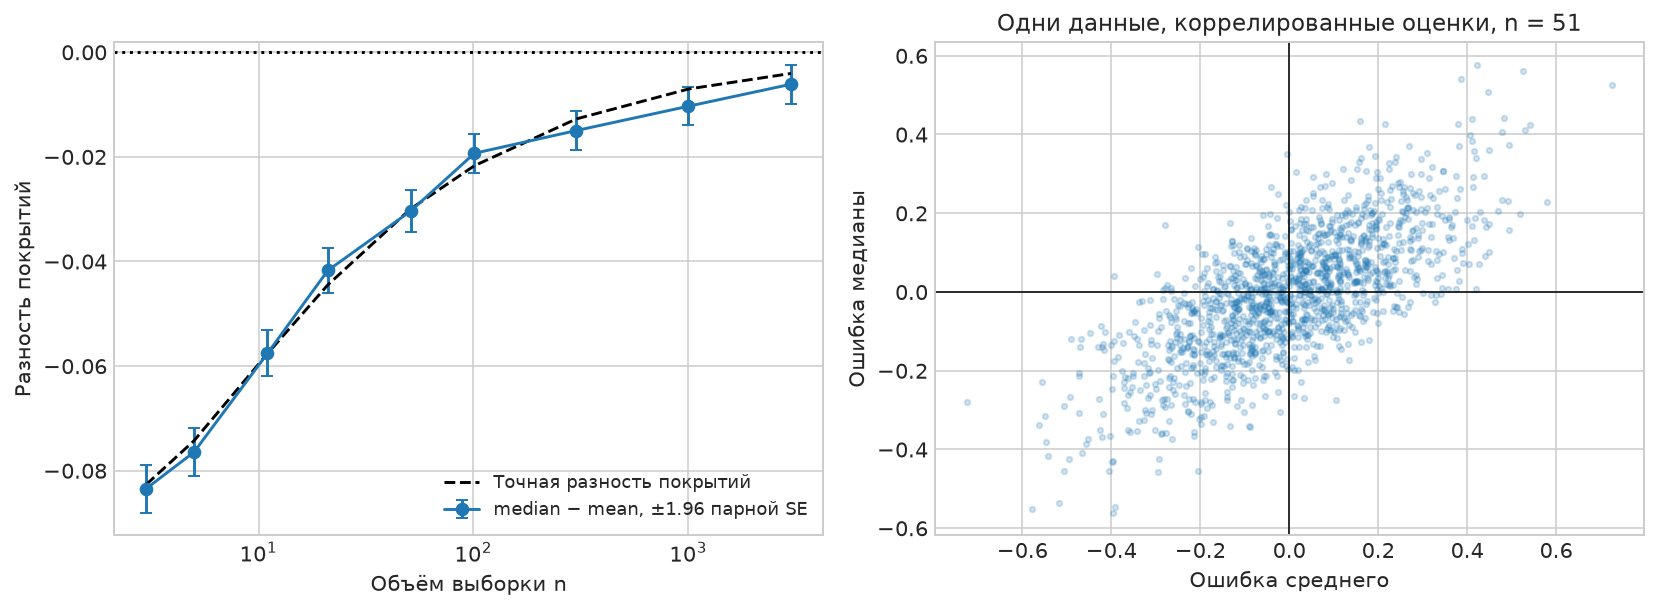

In [14]:
display(paired.round(6))
display(Image(filename=str(result_images["paired"])))

## Чувствительность к доверительному уровню

На рисунке ниже для уровней $90\%$, $95\%$, $99\%$ сопоставляем точное покрытие медианного интервала с номинальным и показываем длину медианного интервала.
Все кривые в этом разделе вычислены по конечновыборочным формулам без нового моделирования.
Увеличение уровня увеличивает $q$, поэтому интервалы расширяются.
Но один лишь более высокий номинальный уровень не устраняет ошибку нормальной аппроксимации: её величина зависит одновременно от $n$ и $\alpha$.

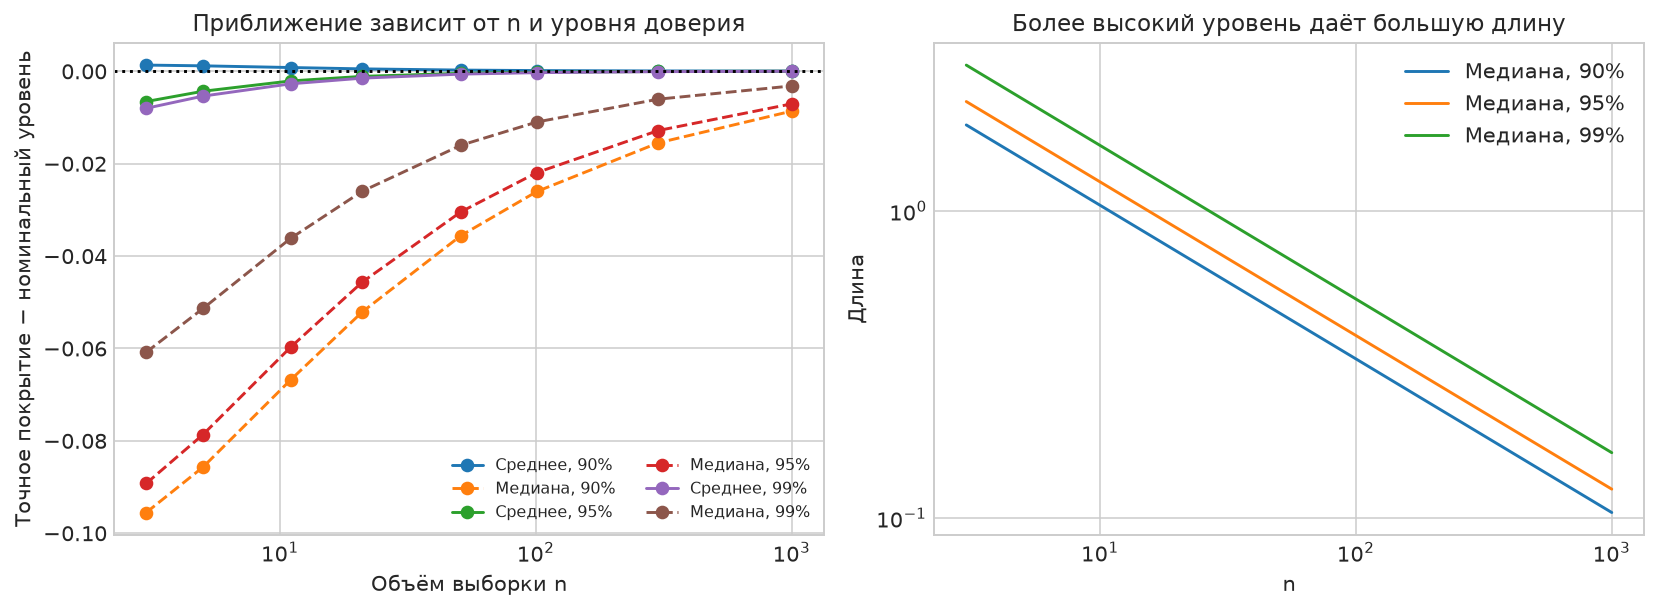

In [15]:
display(Image(filename=str(theory_images["confidence"])))

In [ ]:
summary = table.set_index(["n", "method"])
parts = []
for n in [5, 101, 3001]:
    mean_row = summary.loc[(n, "mean")]
    median_row = summary.loc[(n, "median")]
    parts.append(
        f"При **n={n}** эмпирическое покрытие: среднее **{mean_row.coverage:.4f}**, "
        f"медиана **{median_row.coverage:.4f}** (точное значение для медианы — "
        f"**{median_row.exact_coverage:.4f}**). "
        f"Длины: **{mean_row.mean_length:.4f}** и **{median_row.mean_length:.4f}**."
    )
display(Markdown("\n\n".join(parts)))

При **n=5** эмпирическое покрытие: среднее **0.9475**, медиана **0.8710** (точное значение для медианы — **0.8713**). Длины: **2.4792** и **1.7530**.

При **n=101** эмпирическое покрытие: среднее **0.9506**, медиана **0.9313** (точное значение для медианы — **0.9280**). Длины: **0.5516** и **0.3900**.

При **n=3001** эмпирическое покрытие: среднее **0.9500**, медиана **0.9439** (точное значение для медианы — **0.9459**). Длины: **0.1012** и **0.0716**.

## Выводы

1. Для $\operatorname{Laplace}(\mu,1)$ получены два асимптотических интервала:

   $$I_{\mathrm{mean}}=[\overline X_n-q\sqrt{2/n},\ \overline X_n+q\sqrt{2/n}],$$
   $$I_{\mathrm{median}}=[\widetilde X_n-q/\sqrt n,\ \widetilde X_n+q/\sqrt n].$$

2. Первый основан на ЦПТ для среднего с дисперсией $2$; второй — на предельной нормальности медианы с коэффициентом дисперсии $1/[4f(\mu)^2]=1$.
3. Медианный интервал в $\sqrt2$ раз короче, а асимптотическая дисперсия медианы вдвое меньше. При больших объёмах это преимущество позволяет получать ту же длину примерно на вдвое меньшей выборке.
4. На малых и умеренных объёмах медианный асимптотический интервал заметно недопокрывает. Интервал среднего в проведённом исследовании гораздо ближе к номинальному покрытию. Меньшую длину нельзя оценивать отдельно от фактической вероятности покрытия.
5. Оба метода состоятельны, обе оценки симметричны и несмещённы. Границы стягиваются к $\mu=2$, длины убывают как $1/\sqrt n$, а вероятности покрытия стремятся к $0.95$.
6. Точная конечновыборочная вероятность покрытия медианного интервала подтвердила, что его отставание от $0.95$ — систематическая ошибка приближения.

Рисунки находятся в `images/laplace_location/` и встроены в выполненный ноутбук.